In [1]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 18.4 MB/s  0:00:15
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 53.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


In [2]:
# Install packages if needed (uncomment when running in a fresh environment)
# !pip install -q kagglehub tensorflow scikit-learn seaborn matplotlib pandas

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


TensorFlow version: 2.21.0
GPU available: []


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dog-and-cat-classification-dataset' dataset.
Path to dataset files: /kaggle/input/dog-and-cat-classification-dataset


In [4]:
# Find the directory containing the Cat and Dog folders.
# The dataset is copied into a clean RGB-only version before TensorFlow reads it.

from PIL import Image

def find_class_directory(root):
    root = Path(root)
    candidates = [root] + [p for p in root.rglob("*") if p.is_dir()]

    for folder in candidates:
        try:
            subdirs = [p for p in folder.iterdir() if p.is_dir()]
        except PermissionError:
            continue

        names = {p.name.lower() for p in subdirs}
        if {"cat", "dog"}.issubset(names):
            return folder

    for folder in candidates:
        try:
            subdirs = [p for p in folder.iterdir() if p.is_dir()]
        except PermissionError:
            continue

        names = {p.name.lower() for p in subdirs}
        if {"cats", "dogs"}.issubset(names):
            return folder

    raise FileNotFoundError(
        "Could not find the directory containing the Cat/Dog class folders."
    )

data_dir = find_class_directory(path)
print("Original image directory:", data_dir)
print("Class folders:", [p.name for p in data_dir.iterdir() if p.is_dir()])


# Convert all readable images to RGB JPEGs.
# This fixes dataset images with unusual channel counts (for example 2-channel images).
clean_data_dir = Path("/tmp/cats_dogs_clean_rgb")
if clean_data_dir.exists():
    import shutil
    shutil.rmtree(clean_data_dir)

clean_data_dir.mkdir(parents=True, exist_ok=True)

valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"}

converted = 0
skipped = 0

for class_dir in data_dir.iterdir():
    if not class_dir.is_dir():
        continue

    output_class_dir = clean_data_dir / class_dir.name
    output_class_dir.mkdir(parents=True, exist_ok=True)

    for img_path in class_dir.rglob("*"):
        if img_path.suffix.lower() not in valid_extensions:
            continue

        try:
            with Image.open(img_path) as img:
                img = img.convert("RGB")

                # Give each output image a unique filename to avoid collisions.
                relative_name = "_".join(img_path.relative_to(class_dir).parts)
                output_path = output_class_dir / f"{Path(relative_name).stem}.jpg"

                img.save(output_path, format="JPEG", quality=95)
                converted += 1

        except Exception as e:
            skipped += 1

print(f"Clean RGB images created: {converted}")
print(f"Skipped unreadable/invalid images: {skipped}")
print("Clean dataset directory:", clean_data_dir)

Original image directory: /kaggle/input/dog-and-cat-classification-dataset/PetImages
Class folders: ['Dog', 'Cat']


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:982: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Clean RGB images created: 24998
Skipped unreadable/invalid images: 0
Clean dataset directory: /tmp/cats_dogs_clean_rgb


In [5]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32
SEED = 42

# Use the cleaned RGB dataset.
train_ds, val_ds = tf.keras.utils.image_dataset_from_directory(
    clean_data_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="both",
    seed=SEED,
    shuffle=True
)

class_names = train_ds.class_names
print("Classes:", class_names)

# Recreate validation data without shuffling so predictions/confusion matrix
# always correspond to the correct labels.
_, val_ds = tf.keras.utils.image_dataset_from_directory(
    clean_data_dir,
    labels="inferred",
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="both",
    seed=SEED,
    shuffle=False
)

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)


Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Using 4999 files for validation.
Classes: ['Cat', 'Dog']
Found 24998 files belonging to 2 classes.
Using 19999 files for training.
Using 4999 files for validation.


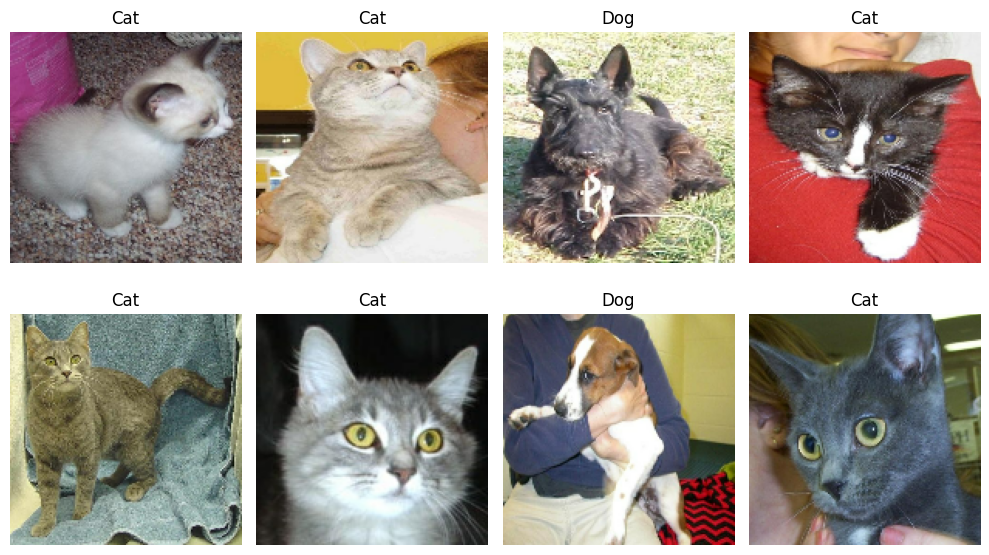

In [6]:
# Preview a few training images
plt.figure(figsize=(10, 6))

for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        ax = plt.subplot(2, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:
# VGG16-specific preprocessing.
# preprocess_input converts RGB -> BGR and subtracts ImageNet channel means.

def vgg_preprocess(images, labels):
    images = preprocess_input(tf.cast(images, tf.float32))
    return images, labels

# Scratch CNN uses simple 0-1 scaling.
def scratch_preprocess(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

vgg_train_ds = train_ds.map(
    vgg_preprocess,
    num_parallel_calls=AUTOTUNE
)
vgg_val_ds = val_ds.map(
    vgg_preprocess,
    num_parallel_calls=AUTOTUNE
)

scratch_train_ds = train_ds.map(
    scratch_preprocess,
    num_parallel_calls=AUTOTUNE
)
scratch_val_ds = val_ds.map(
    scratch_preprocess,
    num_parallel_calls=AUTOTUNE
)

vgg_train_ds = vgg_train_ds.prefetch(AUTOTUNE)
vgg_val_ds = vgg_val_ds.prefetch(AUTOTUNE)
scratch_train_ds = scratch_train_ds.prefetch(AUTOTUNE)
scratch_val_ds = scratch_val_ds.prefetch(AUTOTUNE)

In [8]:
scratch_model = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid")
], name="Scratch_CNN")

scratch_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

scratch_model.summary()

scratch_history = scratch_model.fit(
    scratch_train_ds,
    validation_data=scratch_val_ds,
    epochs=5
)


Model: "Scratch_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 82944)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     5,308,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,327,937 (20.32 MB)

 Trainable params: 5,327,937 (20.32 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 268s 427ms/step - accuracy: 0.6585 - loss: 0.6275 - val_accuracy: 0.8034 - val_loss: 0.4116
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 267s 427ms/step - accuracy: 0.7549 - loss: 0.4975 - val_accuracy: 0.8202 - val_loss: 0.3778
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 266s 425ms/step - accuracy: 0.8218 - loss: 0.3908 - val_accuracy: 0.8846 - val_loss: 0.2828
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 267s 426ms/step - accuracy: 0.8910 - loss: 0.2554 - val_accuracy: 0.9192 - val_loss: 0.2234
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 266s 426ms/step - accuracy: 0.9446 - loss: 0.1450 - val_accuracy: 0.9318 - val_loss: 0.2237


In [9]:
vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(150, 150, 3)
)

# Freeze the entire convolutional feature extractor.
vgg_base.trainable = False

vgg_model = keras.Sequential([
    vgg_base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid")
], name="VGG16_Transfer_Learning")

vgg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

vgg_model.summary()

total_params = vgg_model.count_params()
trainable_params = np.sum([np.prod(v.shape) for v in vgg_model.trainable_weights])

print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,780,481 (56.38 MB)

 Trainable params: 65,793 (257.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Total parameters: 14,780,481
Trainable parameters: 65,793


In [ ]:
vgg_history = vgg_model.fit(
    vgg_train_ds,
    validation_data=vgg_val_ds,
    epochs=8
)

Epoch 1/8
584/625 ━━━━━━━━━━━━━━━━━━━━ 1:45 3s/step - accuracy: 0.9092 - loss: 0.6070